# BB84 Attacks

## Notation and how to read the examples

The four BB84 states are $|0\rangle$, $|1\rangle$, $|+\rangle=(|0\rangle+|1\rangle)/\sqrt2$, and $|-\rangle=(|0\rangle-|1\rangle)/\sqrt2$. Alice and Bob choose their bases independently and keep detected rounds with matching bases. For uniform bases and state-independent detection,

$$Q=\frac{Q_Z+Q_X}{2}.$$

Here $Q_Z$ and $Q_X$ are conditional error probabilities. Reported finite-batch estimates fluctuate; they are not exact identities for each run. An erased signal is excluded from this denominator. No error correction or privacy amplification is performed.

A state is represented by a density matrix $\rho$, and a subsystem state is obtained by tracing out the other factors. Quantum channels act as

$$\mathcal N(\rho)=\sum_\mu K_\mu\rho K_\mu^\dagger,\qquad\sum_\mu K_\mu^\dagger K_\mu=I.$$

For a projector $P_j$, measurement probability and conditional state are

$$p_j=\operatorname{Tr}(P_j\rho),\qquad\rho_j=\frac{P_j\rho P_j}{p_j}.$$

Each class section includes theory, direct method calls, a BB84 example, and its circuit. Methods beginning with an underscore are internal interfaces shown for completeness. Normal protocol use should prefer the public methods. All formulas refer to the supplied implementation and the assumptions stated in the relevant section.


In [1]:
import numpy as np
from qutip import basis, ket2dm, qeye

from modules import *

N = 400

def fresh(): # a fresh 
    return QuantumRegister().load((basis(2, 0) + basis(2, 1)).unit())

## InterceptResendAttack

The measurement outcome is classical information available to Eve immediately. No quantum probe is stored, so memory noise is not applicable to this attack. On a single simulated run `apply` samples a basis and an outcome; on an analytical replay `average_apply` sums over both. These operations serve different purposes: averaging discards Eve's classical record while retaining her disturbance to the signal. `measure_after_sifting` selects her recorded outcomes with the same mask used for Alice's key. It does not retroactively change her measurement basis.

### Mathematical construction

Eve chooses $e\in\{Z,X\}$ uniformly and samples $j$ with $p(j|e)=\operatorname{Tr}(P_j^e\rho)$. The signal becomes
$$\rho_{j,e}=\frac{P_j^e\rho P_j^e}{p(j|e)},\qquad P_j^e=\frac{I+(-1)^j\sigma_e}{2}.$$
These rank-one projectors leave precisely the eigenstate that Eve resends. Without keeping her classical outcome, the map is
$$\mathcal E(\rho)=\frac12\sum_{e=Z,X}\sum_{j=0}^1P_j^e\rho P_j^e.$$
Thus `average_apply` uses Kraus operators $P_j^e/\sqrt2$. On sifted rounds, Eve chose the right basis with probability $1/2$. In the other half, Bob is wrong with probability $1/2$: $Q=1/4$. Eve's success is $\frac12(1)+\frac12(1/2)=3/4$.

### Direct subclass method demonstration
The constructor creates the interaction and validates its parameters. Here `apply` and the subclass readout are invoked explicitly. Intercept–resend uses its own `reset` and `measure_after_sifting`; Breidbart inherits them. Expected wrapper errors are caught so execution continues.

In [2]:
demo = InterceptResendAttack(seed=11)
r = fresh()
demo.apply(r)
demo.capture(r, 0, record=True, detected=True)
print(demo.measure_after_sifting(["X"], [True]))
demo.reset()
print("records after reset:", demo.eve_bits)

[0]
records after reset: []


In [3]:
attack = InterceptResendAttack(seed=11)
bb = BB84(seed=123, number_bits=N)

bb.key_generation(attack, record_rounds=(0,))

print("QBER, loss, sifted length:", bb.qber(), bb.loss_rate(), len(bb.alice_key))
print("QBER: ", bb.qber())
print("Loss: ", bb.loss_rate())
print("Sifted Length")
guesses = bb.eve_guesses(readout="fixed", guess_on_erasure=True)
print("Eve success:", np.mean(guesses == bb.alice_key))

QBER, loss, sifted length: 0.21800947867298578 0.0 211
QBER:  0.21800947867298578
Loss:  0.0
Sifted Length
Eve success: 0.7061611374407583


### Interaction and averaged interaction
`apply` mutates the register; calling the attack itself delegates to `apply`. `average_apply` replaces random choices by their averaged quantum map. Use fresh registers to avoid duplicate probe labels.

In [4]:
direct = InterceptResendAttack(seed=11)
r = fresh()
direct.apply(r)
print("labels / dimensions:", r.labels, r.dims)
r2 = fresh()
direct(r2)
r3 = fresh()
direct.average_apply(r3)
print("averaged signal:", r3.reduced("B").full())


labels / dimensions: ['B'] [2]
averaged signal: [[0.5 +0.j 0.25+0.j]
 [0.25+0.j 0.5 +0.j]]


### BB84 circuit

The diagram below is a recorded, detected round with matching bases. The signal wire is labelled B; probe wires appear when present. Eve’s delayed measurement is included for probe attacks. Noise boxes denote the full channel map; their internal Kraus branches are not individual unitary gates.

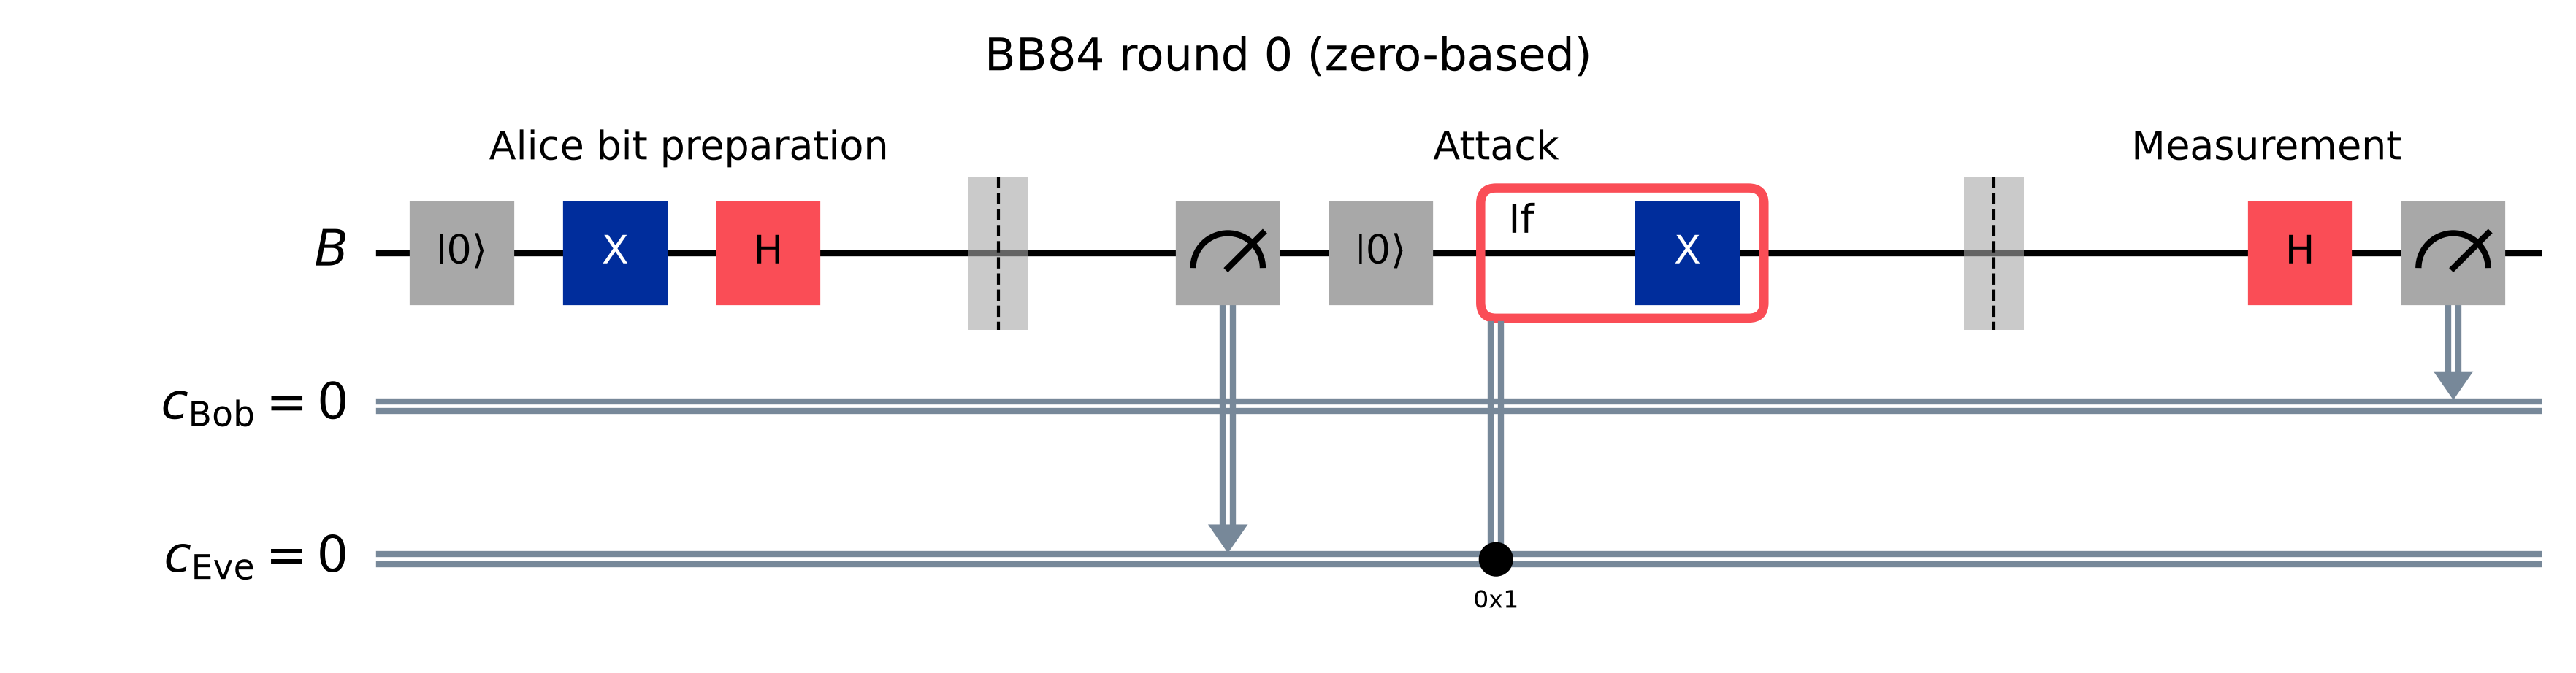

In [5]:
demo_bb = BB84(seed=82, number_bits=24)
demo_attack = InterceptResendAttack(seed=11)
demo_bb.key_generation(demo_attack, record_rounds=range(24))
demo_bb.eve_guesses(readout="fixed", guess_on_erasure=True)
idx = int(np.flatnonzero(demo_bb.sifted_mask)[0])
fig = demo_bb.display(round_index=idx, show=False)
display(fig)

## BreidbartAttack

The intermediate basis trades perfect knowledge of some bits for partial knowledge of every bit. Because the BB84 states are symmetrically arranged around this axis, the same guess rule works for both announced bases. The higher probability of a correct bit guess does not by itself establish that this attack maximizes mutual information. In this class the only newly defined method is the constructor; all other behavior comes from `InterceptResendAttack`.

### Mathematical construction

The angle is a **Bloch-sphere angle** $\alpha=\pi/4$, so
$$M_\alpha=\cos\alpha Z+\sin\alpha X,\quad |b_0\rangle=\cos(\alpha/2)|0\rangle+\sin(\alpha/2)|1\rangle,$$
$$|b_1\rangle=-\sin(\alpha/2)|0\rangle+\cos(\alpha/2)|1\rangle.$$
The ket rotation is $\pi/8$. Eve always measures this basis: the constructor supplies `bases=(np.pi/4,)` to the parent. For either BB84 basis,
$$P_E=\cos^2(\pi/8)=\frac{1+1/\sqrt2}{2}.$$
The probability that measure-and-resend flips Bob's bit is $2\cos^2(\pi/8)\sin^2(\pi/8)=1/4$. All interaction/readout methods are inherited from intercept–resend.

### Direct subclass method demonstration
The constructor creates the interaction and validates its parameters. Here `apply` and the subclass readout are invoked explicitly. Intercept–resend uses its own `reset` and `measure_after_sifting`; Breidbart inherits them. Expected wrapper errors are caught so execution continues.

In [6]:
demo = BreidbartAttack(seed=12)
r = fresh()
demo.apply(r)
demo.capture(r, 0, record=True, detected=True)
print(demo.measure_after_sifting(["X"], [True]))
demo.reset()
print("records after reset:", demo.eve_bits)


[0]
records after reset: []


In [7]:
attack = BreidbartAttack(seed=12)
bb = BB84(seed=123, number_bits=N)
bb.key_generation(attack, record_rounds=(0,))
print("QBER, loss, sifted length:", bb.qber(), bb.loss_rate(), len(bb.alice_key))
guesses = bb.eve_guesses(readout="fixed", guess_on_erasure=True)
print("Eve success:", np.mean(guesses == bb.alice_key))


QBER, loss, sifted length: 0.2985781990521327 0.0 211
Eve success: 0.8151658767772512


### Interaction and averaged interaction
`apply` mutates the register; calling the attack itself delegates to `apply`. `average_apply` replaces random choices by their averaged quantum map. Use fresh registers to avoid duplicate probe labels.

In [8]:
direct = BreidbartAttack(seed=12)
r = fresh()
direct.apply(r)
print("labels / dimensions:", r.labels, r.dims)
r2 = fresh()
direct(r2)
r3 = fresh()
direct.average_apply(r3)
print("averaged signal:", r3.reduced("B").full())


labels / dimensions: ['B'] [2]
averaged signal: [[0.75+0.j 0.25+0.j]
 [0.25+0.j 0.25+0.j]]


### BB84 circuit

The diagram below is a recorded, detected round with matching bases. The signal wire is labelled B; probe wires appear when present. Eve’s delayed measurement is included for probe attacks. Noise boxes denote the full channel map; their internal Kraus branches are not individual unitary gates.

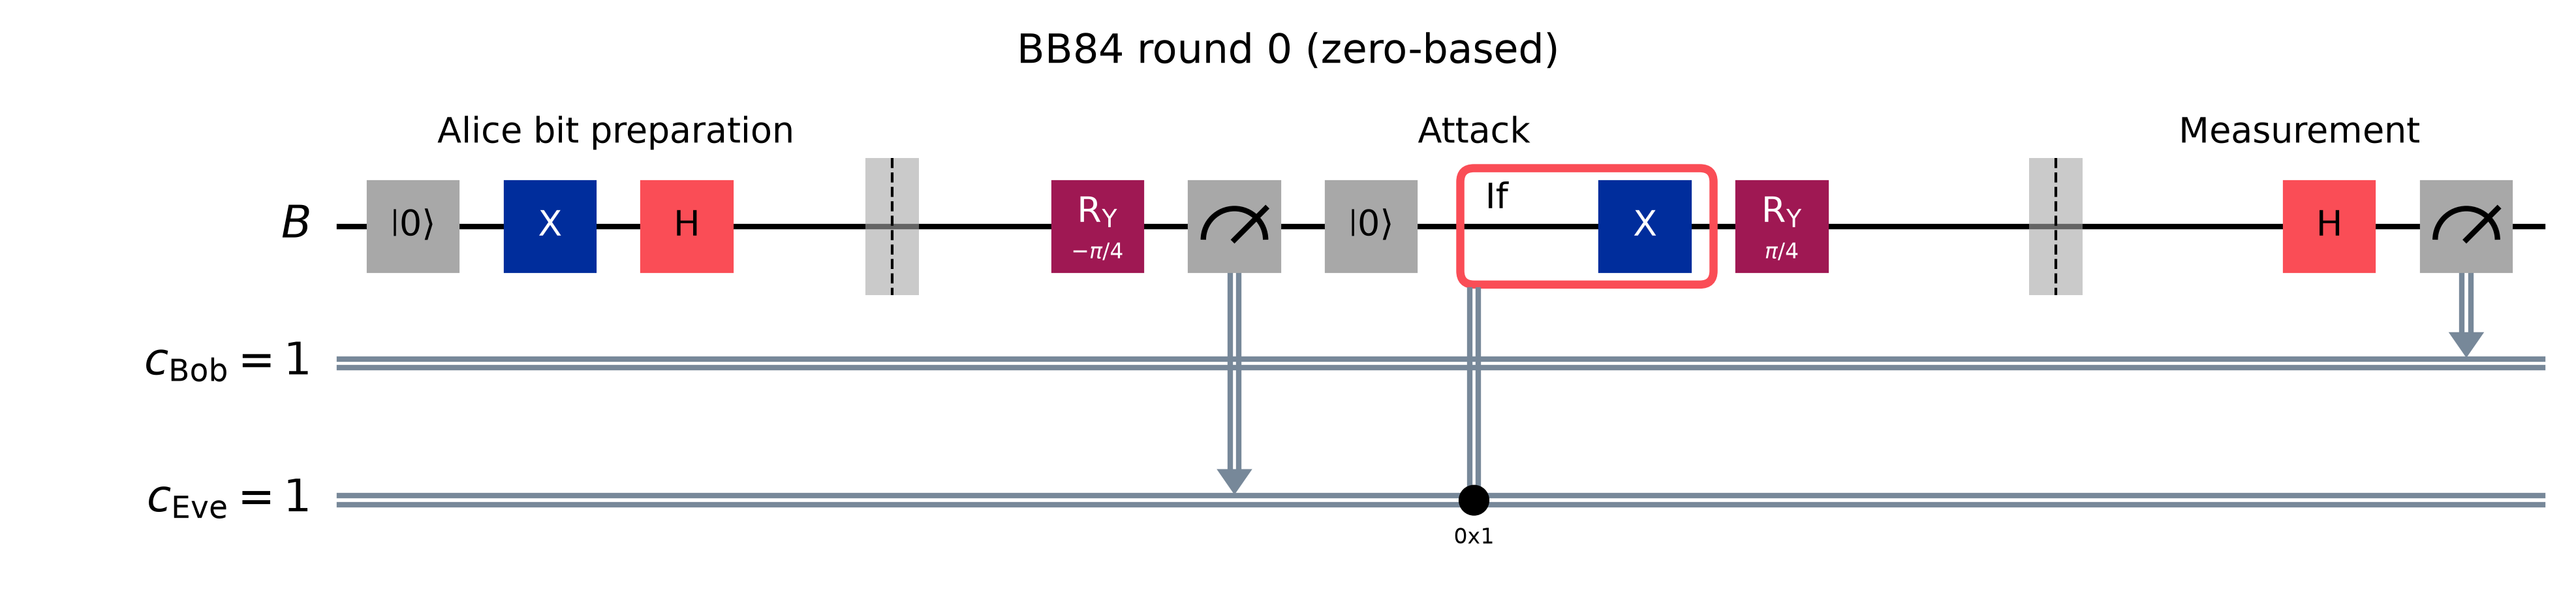

In [9]:
demo_bb = BB84(seed=82, number_bits=24)
demo_attack = BreidbartAttack(seed=12)
demo_bb.key_generation(demo_attack, record_rounds=range(24))
demo_bb.eve_guesses(readout="fixed", guess_on_erasure=True)
idx = int(np.flatnonzero(demo_bb.sifted_mask)[0])
fig = demo_bb.display(round_index=idx, show=False)
display(fig)


## CNOTAttack

The interaction copies the computational-basis label, but cannot copy arbitrary quantum states. The phase distinguishing the two X inputs resides in the joint state and disappears from Eve's reduced density matrix. This explains why delaying her measurement does not help for X bits in this particular attack. In the ideal case the Helstrom difference for X is zero; all outcomes are inconclusive, and the reported success bound includes a fair random guess. Setting `guess_on_erasure=True` includes that random guess in the simulated result.

### Mathematical construction

Initialize $E$ in $|0\rangle$ and apply
$$U_{BE}|b,e\rangle=|b,e\oplus b\rangle.$$
For Z inputs, $|0,0\rangle\mapsto|0,0\rangle$ and $|1,0\rangle\mapsto|1,1\rangle$, so Eve learns Z bits without disturbing them. For X inputs,
$$|\pm,0\rangle\mapsto\frac{|00\rangle\pm|11\rangle}{\sqrt2}.$$
Both reduced states are $I/2$. Therefore $Q_Z=0$, $Q_X=1/2$ and $Q=1/4$. Eve's reference states satisfy $\rho_E^{0,Z}=|0\rangle\langle0|$, $\rho_E^{1,Z}=|1\rangle\langle1|$, while $\rho_E^{0,X}=\rho_E^{1,X}=I/2$. Her average optimal success is $3/4$. Measuring in X cannot recover the relative phase stored in joint correlations.

### Direct subclass method demonstration
The constructor creates the interaction and validates its parameters. Here `apply` and the subclass readout are invoked explicitly. Intercept–resend uses its own `reset` and `measure_after_sifting`; Breidbart inherits them. Expected wrapper errors are caught so execution continues.

In [10]:
demo = CNOTAttack(seed=13)
r = fresh()
demo.apply(r)
print("direct subclass _read_probe:", demo._read_probe(r, "X"))


direct subclass _read_probe: 1


In [11]:
attack = CNOTAttack(seed=13)
bb = BB84(seed=123, number_bits=N)
bb.key_generation(attack, record_rounds=(0,))
print("QBER, loss, sifted length:", bb.qber(), bb.loss_rate(), len(bb.alice_key))
guesses = bb.eve_guesses(readout="fixed", guess_on_erasure=True)
print("Eve success:", np.mean(guesses == bb.alice_key))


QBER, loss, sifted length: 0.20853080568720378 0.0 211
Eve success: 0.7393364928909952


### Interaction and averaged interaction
`apply` mutates the register; calling the attack itself delegates to `apply`. `average_apply` replaces random choices by their averaged quantum map. Use fresh registers to avoid duplicate probe labels.

In [12]:
direct = CNOTAttack(seed=13)
r = fresh()
direct.apply(r)
print("labels / dimensions:", r.labels, r.dims)
r2 = fresh()
direct(r2)
r3 = fresh()
direct.average_apply(r3)
print("averaged signal:", r3.reduced("B").full())


labels / dimensions: ['B', 'E'] [2, 2]
averaged signal: [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]


### Delayed and optimal readout
The reference-state calculation conditions on public detection and incorporates noise. Random guesses on inconclusive outcomes make the sampled success comparable to the Helstrom bound.

In [13]:
print(bb.eve_optimal_success())
optimal = bb.eve_guesses(readout="optimal", guess_on_erasure=True)
print("sampled optimal success:", np.mean(optimal == bb.alice_key))


{'Z': 1.0, 'X': 0.5}
sampled optimal success: 0.7867298578199052


### BB84 circuit

The diagram below is a recorded, detected round with matching bases. The signal wire is labelled B; probe wires appear when present. Eve’s delayed measurement is included for probe attacks. Noise boxes denote the full channel map; their internal Kraus branches are not individual unitary gates.

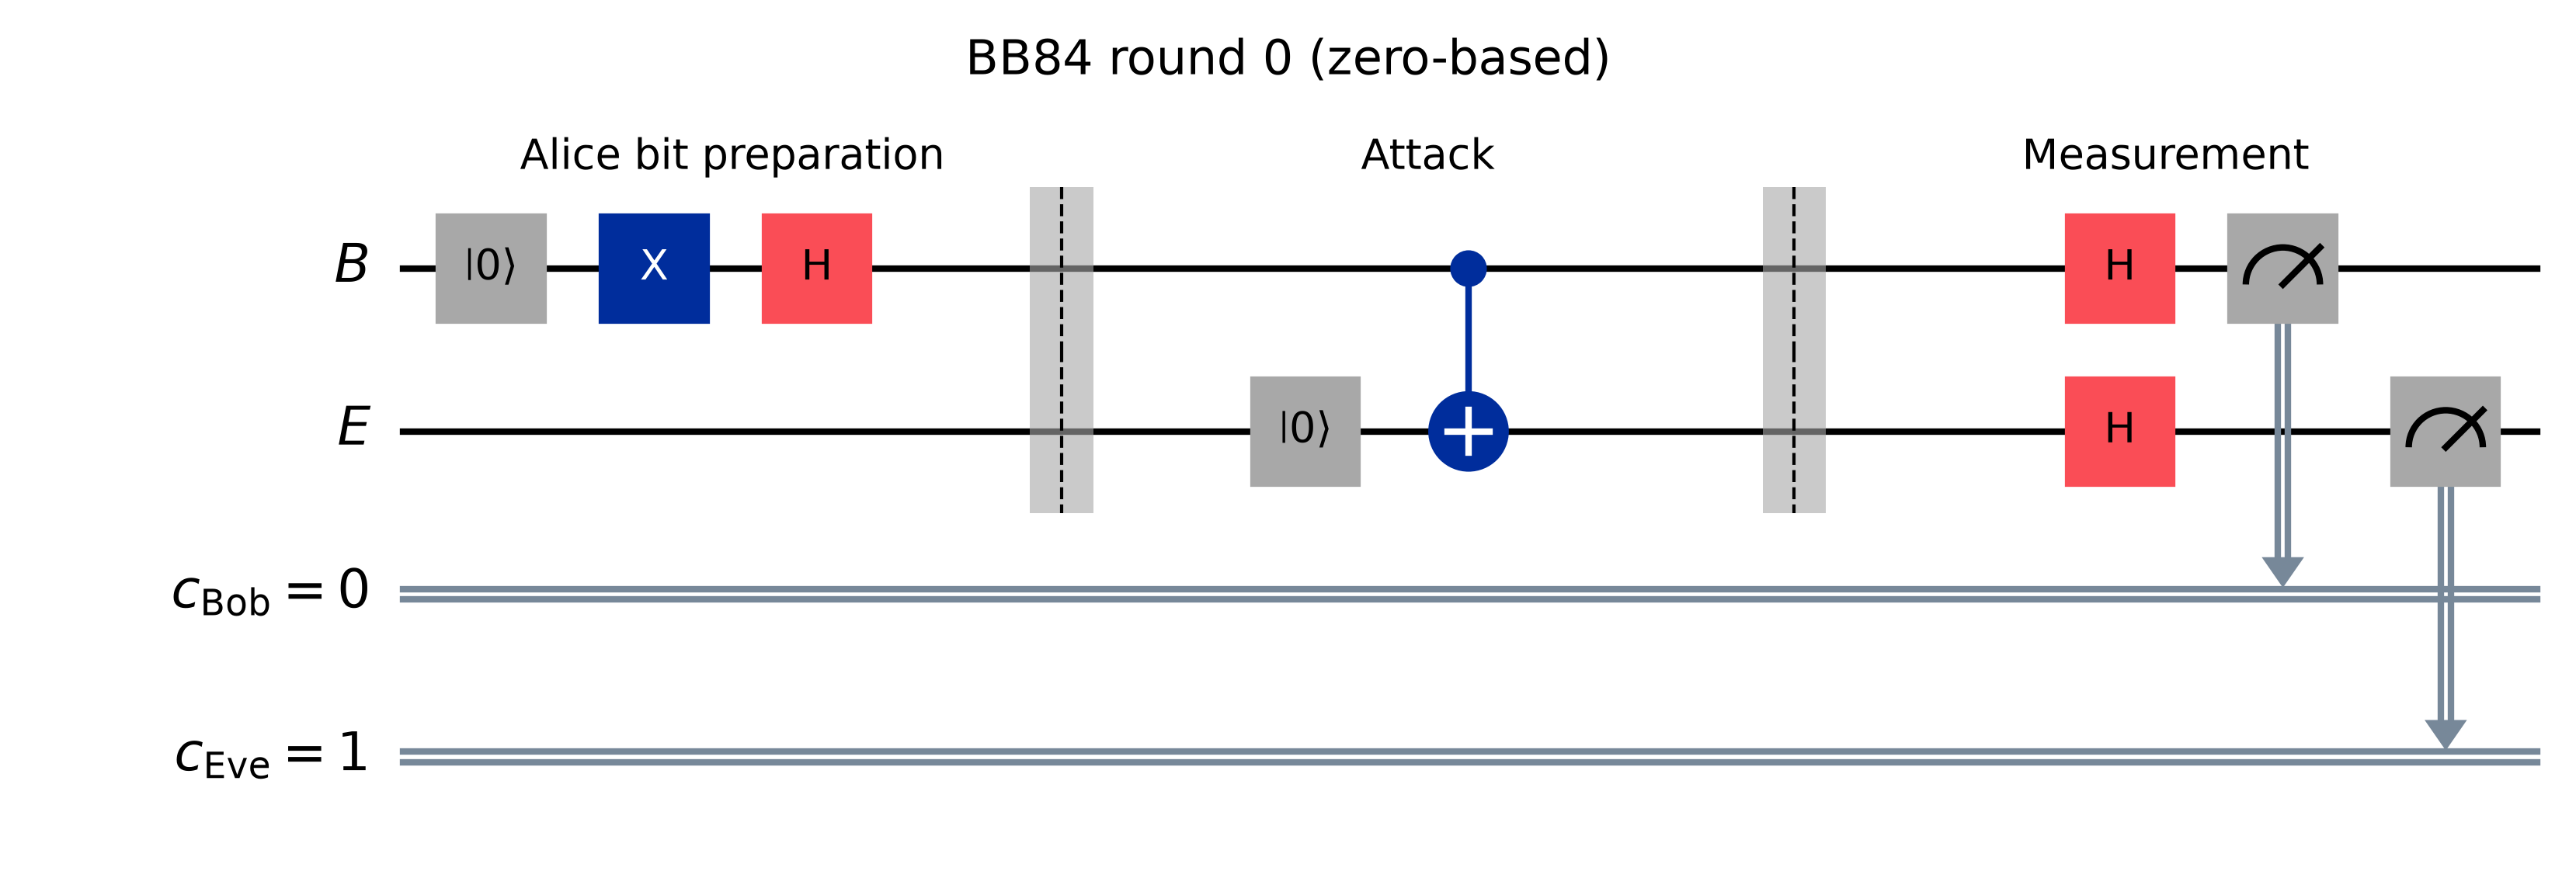

In [14]:
demo_bb = BB84(seed=82, number_bits=24)
demo_attack = CNOTAttack(seed=13)
demo_bb.key_generation(demo_attack, record_rounds=range(24))
demo_bb.eve_guesses(readout="fixed", guess_on_erasure=True)
idx = int(np.flatnonzero(demo_bb.sifted_mask)[0])
fig = demo_bb.display(round_index=idx, show=False)
display(fig)


## FGGNPAttack

The two probes have different roles: the first records information about the signal while the second controls a disturbance. Their initial amplitudes are chosen together so that the disturbance is balanced between the two BB84 bases. At $D=0$, Eve's best success is $1/2$; at $D=1/2$, it reaches unity but Bob's sifted bit is random. The parameter describes the disturbance of this interaction alone; additional transmission channels generally change the measured QBER. The X readout uses two sequential local measurements whose classical parity forms the guess; the optimal readout may instead use one joint measurement on both probes.

### Mathematical construction

For chosen disturbance $D\in[0,1/2]$, define
$$\delta=\frac12-\sqrt{D(1-D)},\quad |e_0\rangle=\sqrt{1-\delta}|0\rangle+\sqrt\delta|1\rangle,\quad |f_0\rangle=\sqrt{1-D}|0\rangle+\sqrt D|1\rangle.$$
The order is $\mathrm{CNOT}_{B\to E}$ followed by $\mathrm{CNOT}_{F\to B}$:
$$|b,e,f\rangle\longmapsto|b\oplus f,e\oplus b,f\rangle.$$
In Z, $f=1$ causes Bob's error, so $Q_Z=D$. In X, tracing E after the first CNOT shrinks Bob's X coherence by
$$\langle e_0|X|e_0\rangle=2\sqrt{\delta(1-\delta)}=1-2D,$$
so $Q_X=D$ as well. Eve reads E in Z, with success $1-\delta=1/2+\sqrt{D(1-D)}$. For X she measures both probes and uses $e\oplus f$. This is the fixed parity policy implemented by `_read_probe`. If F is erased it returns UNKNOWN; if only E is erased it uses F alone. With extra noise the original fixed policy need not remain optimal.

### Direct subclass method demonstration
The constructor creates the interaction and validates its parameters. Here `apply` and the subclass readout are invoked explicitly. Intercept–resend uses its own `reset` and `measure_after_sifting`; Breidbart inherits them. Expected wrapper errors are caught so execution continues.

In [15]:
demo = FGGNPAttack(disturbance=0.1, seed=14)
r = fresh()
demo.apply(r)
print("direct subclass _read_probe:", demo._read_probe(r, "X"))

direct subclass _read_probe: 0


In [16]:
attack = FGGNPAttack(disturbance=0.1, seed=14)
bb = BB84(seed=123, number_bits=N)
bb.key_generation(attack, record_rounds=(0,))
print("QBER, loss, sifted length:", bb.qber(), bb.loss_rate(), len(bb.alice_key))
guesses = bb.eve_guesses(readout="fixed", guess_on_erasure=True)
print("Eve success:", np.mean(guesses == bb.alice_key))


QBER, loss, sifted length: 0.0995260663507109 0.0 211
Eve success: 0.7772511848341233


### Interaction and averaged interaction
`apply` mutates the register; calling the attack itself delegates to `apply`. `average_apply` replaces random choices by their averaged quantum map. Use fresh registers to avoid duplicate probe labels.

In [17]:
direct = FGGNPAttack(disturbance=0.1, seed=14)
r = fresh()
direct.apply(r)
print("labels / dimensions:", r.labels, r.dims)
r2 = fresh()
direct(r2)
r3 = fresh()
direct.average_apply(r3)
print("averaged signal:", r3.reduced("B").full())


labels / dimensions: ['B', 'E', 'F'] [2, 2, 2]
averaged signal: [[0.5+0.j 0.4+0.j]
 [0.4+0.j 0.5+0.j]]


### Delayed and optimal readout
The reference-state calculation conditions on public detection and incorporates noise. Random guesses on inconclusive outcomes make the sampled success comparable to the Helstrom bound.

In [18]:
print(bb.eve_optimal_success())
optimal = bb.eve_guesses(readout="optimal", guess_on_erasure=True)
print("sampled optimal success:", np.mean(optimal == bb.alice_key))


{'Z': 0.8, 'X': 0.7999999999999999}
sampled optimal success: 0.8104265402843602


### BB84 circuit

The diagram below is a recorded, detected round with matching bases. The signal wire is labelled B; probe wires appear when present. Eve’s delayed measurement is included for probe attacks. Noise boxes denote the full channel map; their internal Kraus branches are not individual unitary gates.

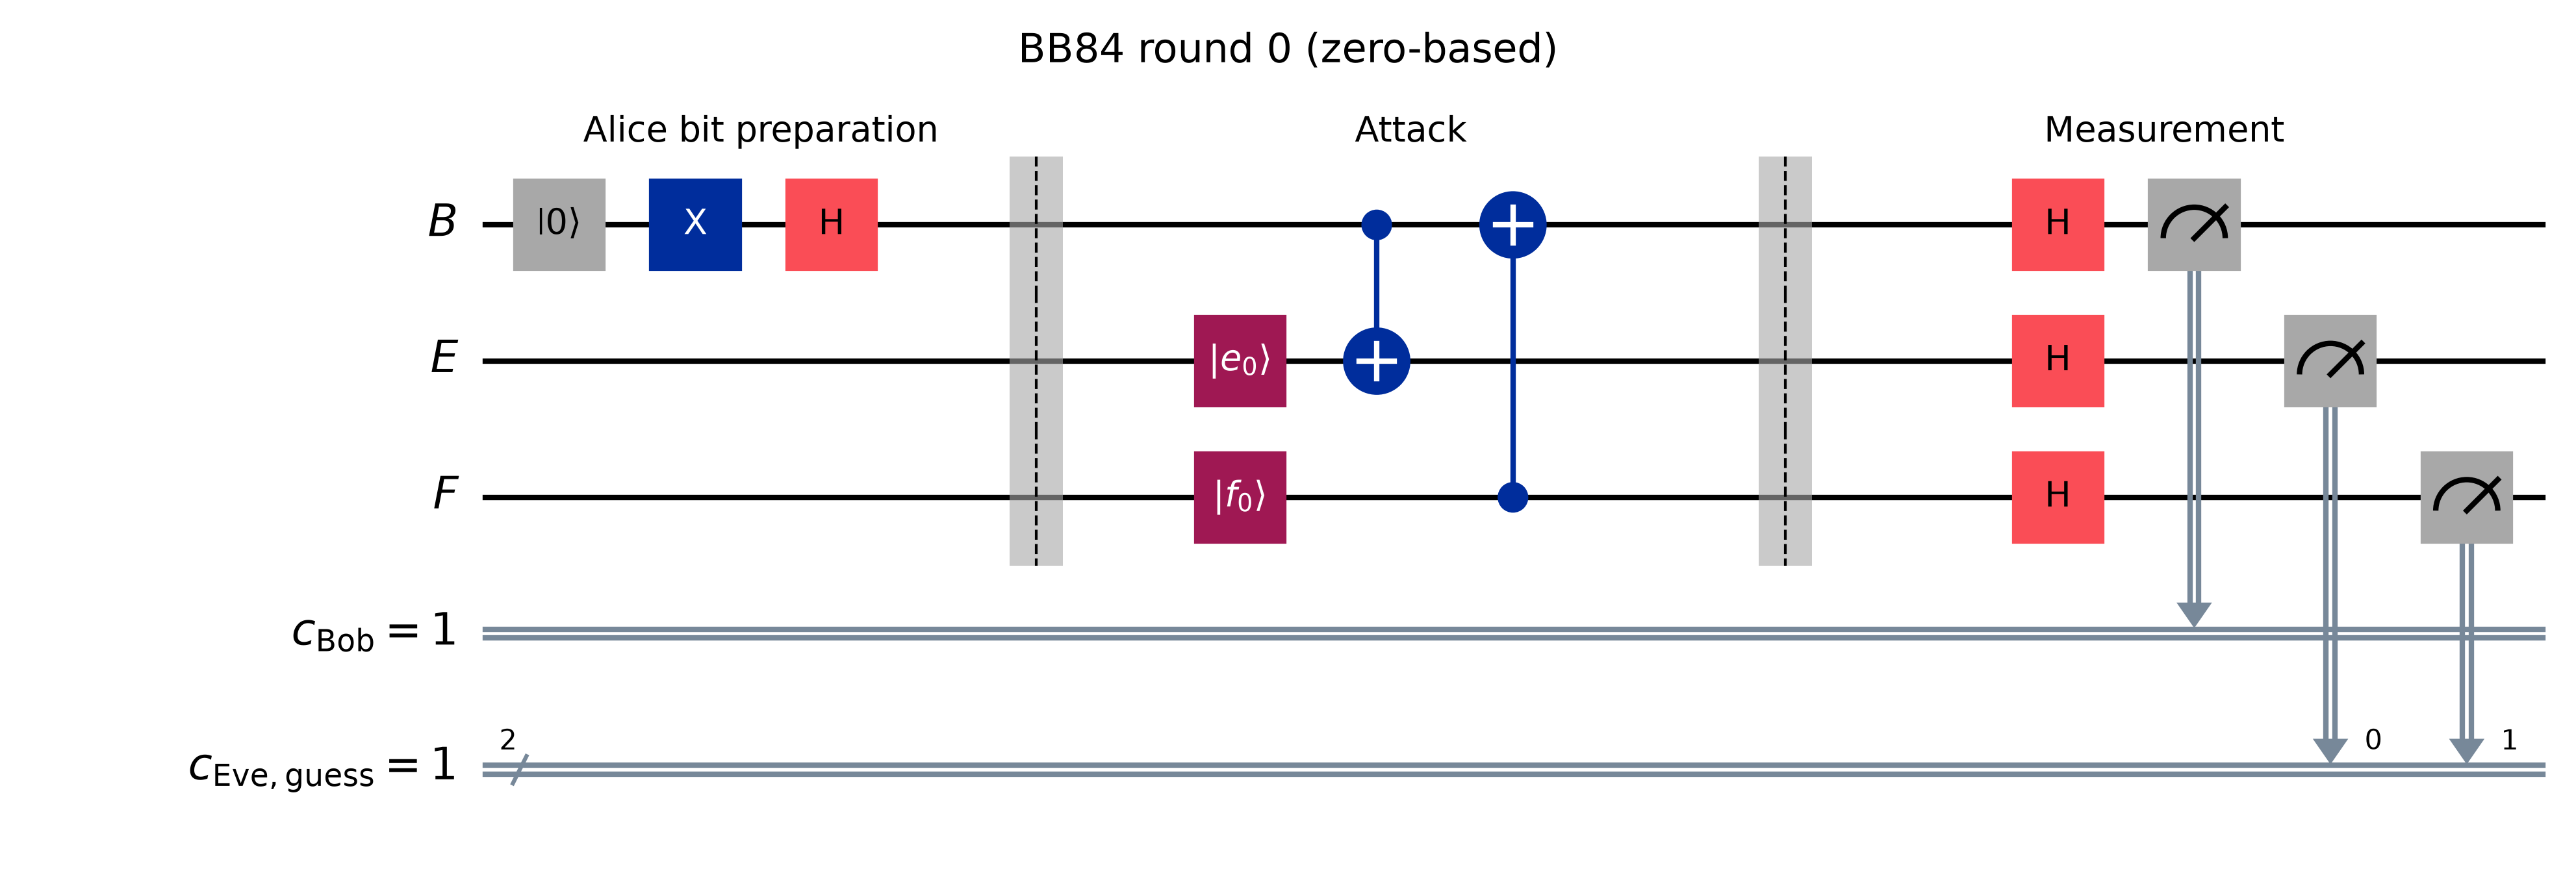

In [19]:
demo_bb = BB84(seed=82, number_bits=24)
demo_attack = FGGNPAttack(disturbance=0.1, seed=14)
demo_bb.key_generation(demo_attack, record_rounds=range(24))
demo_bb.eve_guesses(readout="fixed", guess_on_erasure=True)
idx = int(np.flatnonzero(demo_bb.sifted_mask)[0])
fig = demo_bb.display(round_index=idx, show=False)
display(fig)


## PartialSwapAttack

The reference state of the probe selects a preferred direction. Consequently this interaction is not the same as a symmetric cloning machine even though the two BB84 basis-averaged error rates happen to agree. Bob's off-diagonal element is multiplied by $c e^{-i\theta}$, which includes both attenuation and rotation. Eve's off-diagonal element is multiplied by $i s e^{-i\theta}$ for a general input. Their real parts give the fixed-basis measurement performance, whereas Helstrom discrimination can exploit the complete complex density matrix.

### Mathematical construction

Because $S=\mathrm{SWAP}$ obeys $S^2=I$,
$$U_\theta=e^{-i\theta S}=\cos\theta I-i\sin\theta S.$$
For a blank $|0\rangle_E$,
$$|00\rangle\mapsto e^{-i\theta}|00\rangle,\qquad |10\rangle\mapsto c|10\rangle-is|01\rangle,$$
where $c=\cos\theta$, $s=\sin\theta$. After tracing Eve, Bob's Kraus operators can be written
$$K_0=\operatorname{diag}(e^{-i\theta},c),\qquad K_1=-is|0\rangle\langle1|.$$
For equiprobable bits $Q_Z=s^2/2$. For X, the real coherence is multiplied by $c\cos\theta=c^2$, hence $Q_X=s^2/2$. The off-diagonal phase means Eve's fixed X measurement need not coincide with her Helstrom measurement. At $\theta=\pi/2$, Bob receives the blank and Eve receives the input, up to a global phase.

### Direct subclass method demonstration
The constructor creates the interaction and validates its parameters. Here `apply` and the subclass readout are invoked explicitly. Intercept–resend uses its own `reset` and `measure_after_sifting`; Breidbart inherits them. Expected wrapper errors are caught so execution continues.

In [20]:
demo = PartialSwapAttack(theta=np.pi / 4, seed=15)
r = fresh()
demo.apply(r)
print("direct subclass _read_probe:", demo._read_probe(r, "X"))


direct subclass _read_probe: 0


In [21]:
attack = PartialSwapAttack(theta=np.pi / 4, seed=15)
bb = BB84(seed=123, number_bits=N)
bb.key_generation(attack, record_rounds=(0,))
print("QBER, loss, sifted length:", bb.qber(), bb.loss_rate(), len(bb.alice_key))
guesses = bb.eve_guesses(readout="fixed", guess_on_erasure=True)
print("Eve success:", np.mean(guesses == bb.alice_key))


QBER, loss, sifted length: 0.25118483412322273 0.0 211
Eve success: 0.8151658767772512


### Interaction and averaged interaction
`apply` mutates the register; calling the attack itself delegates to `apply`. `average_apply` replaces random choices by their averaged quantum map. Use fresh registers to avoid duplicate probe labels.

In [22]:
direct = PartialSwapAttack(theta=np.pi / 4, seed=15)
r = fresh()
direct.apply(r)
print("labels / dimensions:", r.labels, r.dims)
r2 = fresh()
direct(r2)
r3 = fresh()
direct.average_apply(r3)
print("averaged signal:", r3.reduced("B").full())


labels / dimensions: ['B', 'E'] [2, 2]
averaged signal: [[0.75+0.j   0.25-0.25j]
 [0.25+0.25j 0.25+0.j  ]]


### Delayed and optimal readout
The reference-state calculation conditions on public detection and incorporates noise. Random guesses on inconclusive outcomes make the sampled success comparable to the Helstrom bound.

In [23]:
print(bb.eve_optimal_success())
optimal = bb.eve_guesses(readout="optimal", guess_on_erasure=True)
print("sampled optimal success:", np.mean(optimal == bb.alice_key))


{'Z': 0.75, 'X': 0.8535533905932737}
sampled optimal success: 0.8104265402843602


### BB84 circuit

The diagram below is a recorded, detected round with matching bases. The signal wire is labelled B; probe wires appear when present. Eve’s delayed measurement is included for probe attacks. Noise boxes denote the full channel map; their internal Kraus branches are not individual unitary gates.

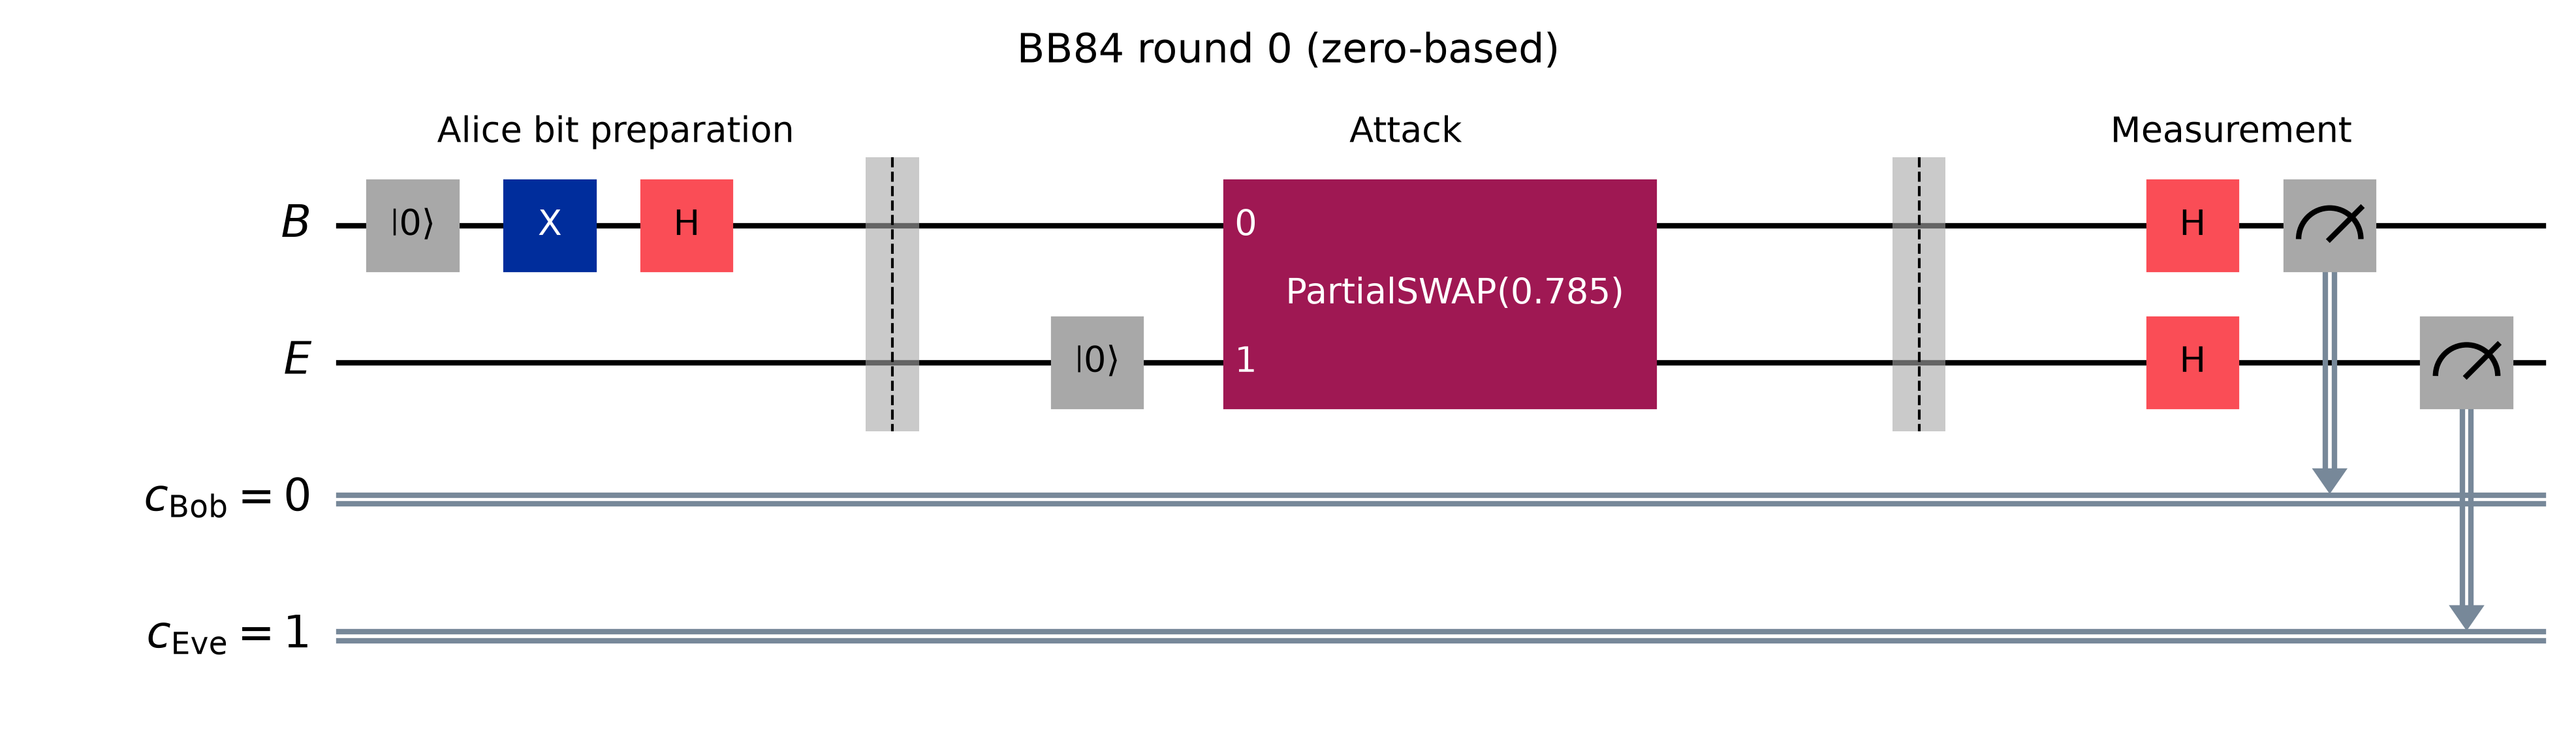

In [24]:
demo_bb = BB84(seed=82, number_bits=24)
demo_attack = PartialSwapAttack(theta=np.pi / 4, seed=15)
demo_bb.key_generation(demo_attack, record_rounds=range(24))
demo_bb.eve_guesses(readout="fixed", guess_on_erasure=True)
idx = int(np.flatnonzero(demo_bb.sifted_mask)[0])
fig = demo_bb.display(round_index=idx, show=False)
display(fig)


## PhaseCovariantCloningAttack

The cloner preserves the symmetry of the great circle containing the BB84 states. Its fidelity formulas apply to those states, not to arbitrary points on the Bloch sphere. The output clones can be correlated and need not be pure. Rotation of both output systems is essential: without undoing the change of coordinates, measuring Eve in the original BB84 basis would not implement the claimed readout. At the symmetric angle both parties receive approximate copies, consistent with the impossibility of perfect cloning.

### Mathematical construction

On the equator the blank-probe isometry is
$$|00\rangle\mapsto|00\rangle,\qquad |10\rangle\mapsto c|10\rangle+s|01\rangle.$$
The full unitary completes this with $|01\rangle\mapsto c|01\rangle-s|10\rangle$ and $|11\rangle\mapsto|11\rangle$. The code uses $R=(I-iX)/\sqrt2$ to rotate the BB84 great circle:
$$U=(R^\dagger\otimes R^\dagger)U_{xy}(R\otimes I).$$
For input $|\psi_\phi\rangle=(|0\rangle+e^{i\phi}|1\rangle)/\sqrt2$, the equatorial Bloch components of Bob and Eve shrink by $c$ and $s$, respectively. Therefore
$$F_B=\frac{1+\cos\theta}{2},\quad F_E=\frac{1+\sin\theta}{2},\quad Q=1-F_B.$$
At $\theta=\pi/4$, $F_B=F_E\simeq0.8536$. The unequal fidelities interpolate between preserving Bob's signal and transferring its information to Eve.

### Direct subclass method demonstration
The constructor creates the interaction and validates its parameters. Here `apply` and the subclass readout are invoked explicitly. Intercept–resend uses its own `reset` and `measure_after_sifting`; Breidbart inherits them. Expected wrapper errors are caught so execution continues.

In [25]:
demo = PhaseCovariantCloningAttack(theta=np.pi / 4, seed=16)
r = fresh()
demo.apply(r)
print("direct subclass _read_probe:", demo._read_probe(r, "X"))


direct subclass _read_probe: 0


In [26]:
attack = PhaseCovariantCloningAttack(theta=np.pi / 4, seed=16)
bb = BB84(seed=123, number_bits=N)
bb.key_generation(attack, record_rounds=(0,))
print("QBER, loss, sifted length:", bb.qber(), bb.loss_rate(), len(bb.alice_key))
guesses = bb.eve_guesses(readout="fixed", guess_on_erasure=True)
print("Eve success:", np.mean(guesses == bb.alice_key))


QBER, loss, sifted length: 0.14691943127962084 0.0 211
Eve success: 0.8862559241706162


### Interaction and averaged interaction
`apply` mutates the register; calling the attack itself delegates to `apply`. `average_apply` replaces random choices by their averaged quantum map. Use fresh registers to avoid duplicate probe labels.

In [27]:
direct = PhaseCovariantCloningAttack(theta=np.pi / 4, seed=16)
r = fresh()
direct.apply(r)
print("labels / dimensions:", r.labels, r.dims)
r2 = fresh()
direct(r2)
r3 = fresh()
direct.average_apply(r3)
print("averaged signal:", r3.reduced("B").full())


labels / dimensions: ['B', 'E'] [2, 2]
averaged signal: [[0.5       +0.j   0.35355339-0.25j]
 [0.35355339+0.25j 0.5       +0.j  ]]


### Delayed and optimal readout
The reference-state calculation conditions on public detection and incorporates noise. Random guesses on inconclusive outcomes make the sampled success comparable to the Helstrom bound.

In [28]:
print(bb.eve_optimal_success())
optimal = bb.eve_guesses(readout="optimal", guess_on_erasure=True)
print("sampled optimal success:", np.mean(optimal == bb.alice_key))


{'Z': 0.8535533905932735, 'X': 0.8535533905932735}
sampled optimal success: 0.8625592417061612


### BB84 circuit

The diagram below is a recorded, detected round with matching bases. The signal wire is labelled B; probe wires appear when present. Eve’s delayed measurement is included for probe attacks. Noise boxes denote the full channel map; their internal Kraus branches are not individual unitary gates.

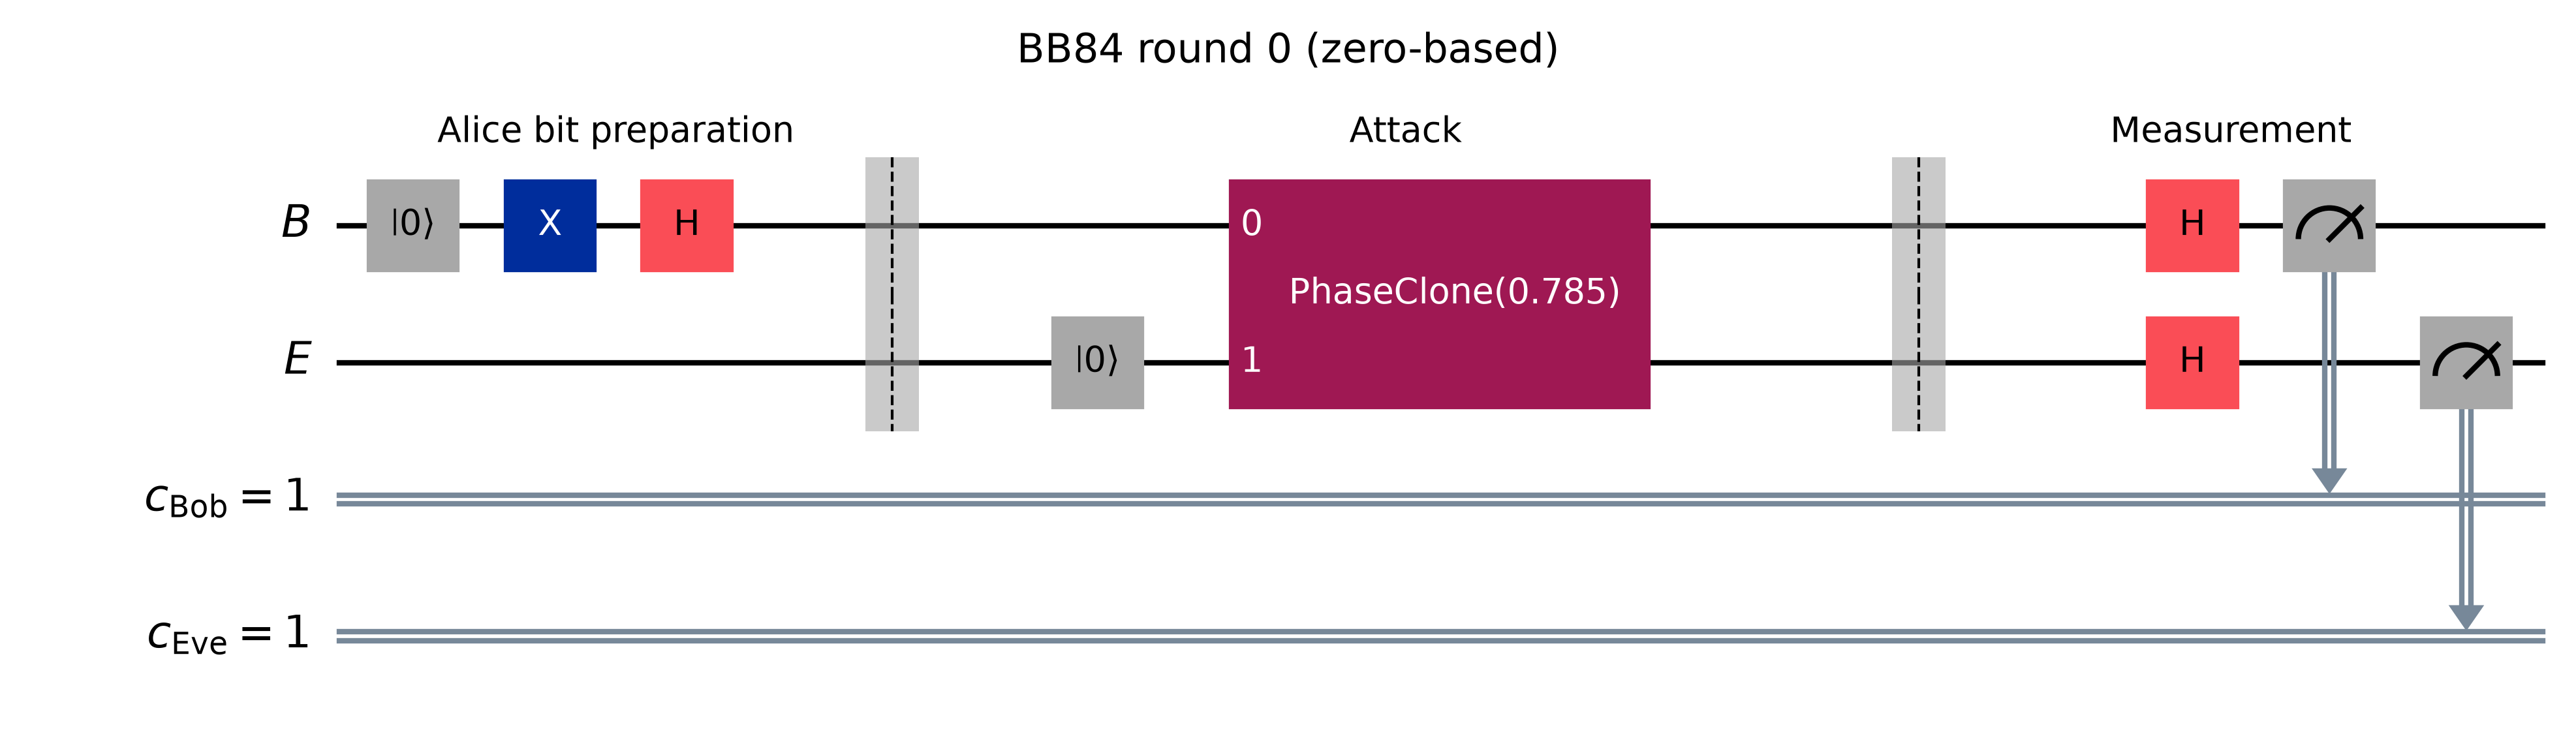

In [29]:
demo_bb = BB84(seed=82, number_bits=24)
demo_attack = PhaseCovariantCloningAttack(theta=np.pi / 4, seed=16)
demo_bb.key_generation(demo_attack, record_rounds=range(24))
demo_bb.eve_guesses(readout="fixed", guess_on_erasure=True)
idx = int(np.flatnonzero(demo_bb.sifted_mask)[0])
fig = demo_bb.display(round_index=idx, show=False)
display(fig)


## NoiseAdaptiveHelstromAttack

The conditional states are calculated from the saved run configuration, including noise and the public detection event. Bob's secret bit is never provided to the measurement policy. The simulator may store a probe state conditioned on sampled legitimate outcomes to reproduce joint statistics, but the chosen measurement depends only on the reference ensemble and public basis. With unequal conditional priors, an erased probe need not be inconclusive: the best decision may favor the more likely bit. A zero eigenvalue means the two weighted hypotheses have equal probability on that subspace.

### Mathematical construction

Let $\rho_b$ be Eve's probe state conditioned on Alice's bit $b$, announced basis, and Bob detecting the signal. For priors $p_b$, define
$$\Delta=p_0\rho_0-p_1\rho_1,\qquad P_{\rm guess}=\frac{1+\|\Delta\|_1}{2}.$$
Project onto the positive eigenspace to guess 0 and the negative eigenspace to guess 1. A zero eigenvalue gives no preference. The code passes $\sigma_b=2p_b\rho_b$ to its equal-prior helpers, so
$$P_{\rm guess}=\frac12+\frac14\|\sigma_0-\sigma_1\|_1.$$
Memory noise changes $\rho_b$ and can change the optimal eigenvectors. `apply` and `average_apply` delegate to the wrapped interaction; the wrapper does not introduce another signal coupling. Its `_read_probe` deliberately raises an error because a fixed readout has not been defined. `measure_after_sifting` requires reference states supplied by BB84's optimal mode.

### Direct subclass method demonstration
The constructor creates the interaction and validates its parameters. Here `apply` and the subclass readout are invoked explicitly. Intercept–resend uses its own `reset` and `measure_after_sifting`; Breidbart inherits them. Expected wrapper errors are caught so execution continues.

In [30]:
demo = NoiseAdaptiveHelstromAttack(CNOTAttack(seed=17), seed=18)
r = fresh()
demo.apply(r)
try:
    demo._read_probe(r, "Z")
except ValueError as error:
    print("Expected fixed-readout rejection:", error)
try:
    demo.measure_after_sifting([], [])
except ValueError as error:
    print("Expected missing-reference rejection:", error)


Expected fixed-readout rejection: NoiseAdaptiveHelstromAttack requires reference states; use BB84.eve_guesses(readout='optimal')
Expected missing-reference rejection: Noise-adaptive readout needs BB84's conditional probe states; call BB84.eve_guesses(readout='optimal')


In [31]:
attack = NoiseAdaptiveHelstromAttack(CNOTAttack(seed=17), seed=18)
bb = BB84(seed=123, number_bits=N)
bb.key_generation(attack, record_rounds=(0,))
print("QBER, loss, sifted length:", bb.qber(), bb.loss_rate(), len(bb.alice_key))
guesses = bb.eve_guesses(readout="optimal", guess_on_erasure=True)
print("Eve success:", np.mean(guesses == bb.alice_key))


QBER, loss, sifted length: 0.20853080568720378 0.0 211
Eve success: 0.7393364928909952


### Interaction and averaged interaction
`apply` mutates the register; calling the attack itself delegates to `apply`. `average_apply` replaces random choices by their averaged quantum map. Use fresh registers to avoid duplicate probe labels.

In [32]:
direct = NoiseAdaptiveHelstromAttack(CNOTAttack(seed=17), seed=18)
r = fresh()
direct.apply(r)
print("labels / dimensions:", r.labels, r.dims)
r2 = fresh()
direct(r2)
r3 = fresh()
direct.average_apply(r3)
print("averaged signal:", r3.reduced("B").full())


labels / dimensions: ['B', 'E'] [2, 2]
averaged signal: [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]


### Delayed and optimal readout
The reference-state calculation conditions on public detection and incorporates noise. Random guesses on inconclusive outcomes make the sampled success comparable to the Helstrom bound.

In [33]:
print(bb.eve_optimal_success())
optimal = bb.eve_guesses(readout="optimal", guess_on_erasure=True)
print("sampled optimal success:", np.mean(optimal == bb.alice_key))


{'Z': 1.0, 'X': 0.5}
sampled optimal success: 0.7393364928909952


### BB84 circuit

The diagram below is a recorded, detected round with matching bases. The signal wire is labelled B; probe wires appear when present. Eve’s delayed measurement is included for probe attacks. Noise boxes denote the full channel map; their internal Kraus branches are not individual unitary gates.

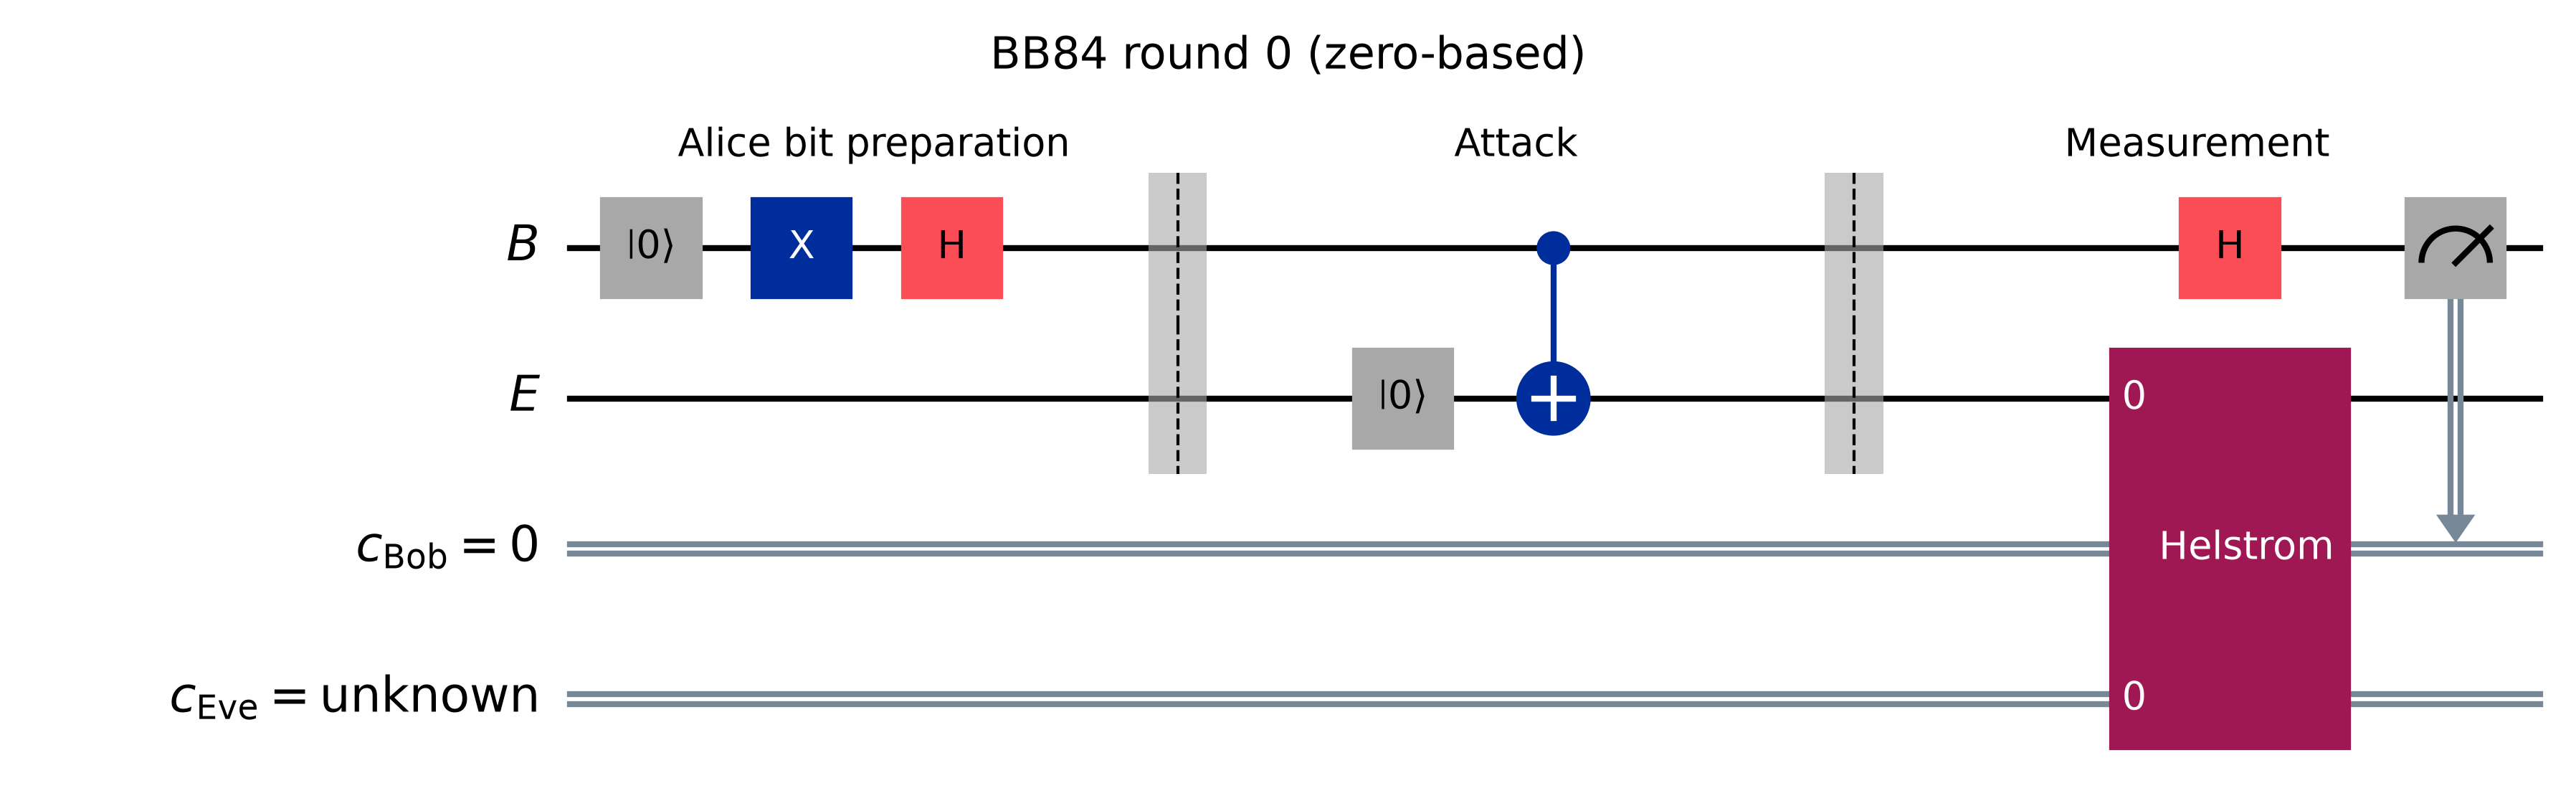

In [34]:
demo_bb = BB84(seed=82, number_bits=24)
demo_attack = NoiseAdaptiveHelstromAttack(CNOTAttack(seed=17), seed=18)
demo_bb.key_generation(demo_attack, record_rounds=range(24))
demo_bb.eve_guesses(readout="optimal", guess_on_erasure=True)
idx = int(np.flatnonzero(demo_bb.sifted_mask)[0])
fig = demo_bb.display(round_index=idx, show=False)
display(fig)


## Shared Attack lifecycle and internal helpers
`reset` clears captured records but does not rewind the RNG. `capture` must use consecutive indices. `_probe_register` reconstructs a fresh measurable copy; `_sifting_inputs` validates alignment and detection. `_read_probe` is the subclass’s fixed policy; `_read_optimal` consumes explicit Helstrom projectors. Private methods below are educational inspection points; normal applications should call `BB84.eve_guesses`.

In [35]:
a = CNOTAttack(seed=44)
r = fresh()
a.apply(r)
r.measure("B", "X", np.random.default_rng(5))
a.capture(r, 0, record=True, detected=True)
bases, mask = a._sifting_inputs(["X"], [True])
print(a._check_labels("E", 1))
print(a._read_probe(a._probe_register(0), "X"))
print(a.measure_after_sifting(bases, mask, guess_on_erasure=True))
rho0, rho1 = (ket2dm(basis(2, 0)), ket2dm(basis(2, 1)))
print(a._read_optimal(a._probe_register(0), helstrom_projectors(rho0, rho1)))
a.reset()
print(a.round_count, a.probe_states)


('E',)
1
[1]
0
0 []


## Noise and a recorded circuit
Memory noise acts after coupling and before delayed readout. A drawing of a retained sifted round includes Eve’s delayed measurement. UNKNOWN=-1 is an abstention, not a bit.

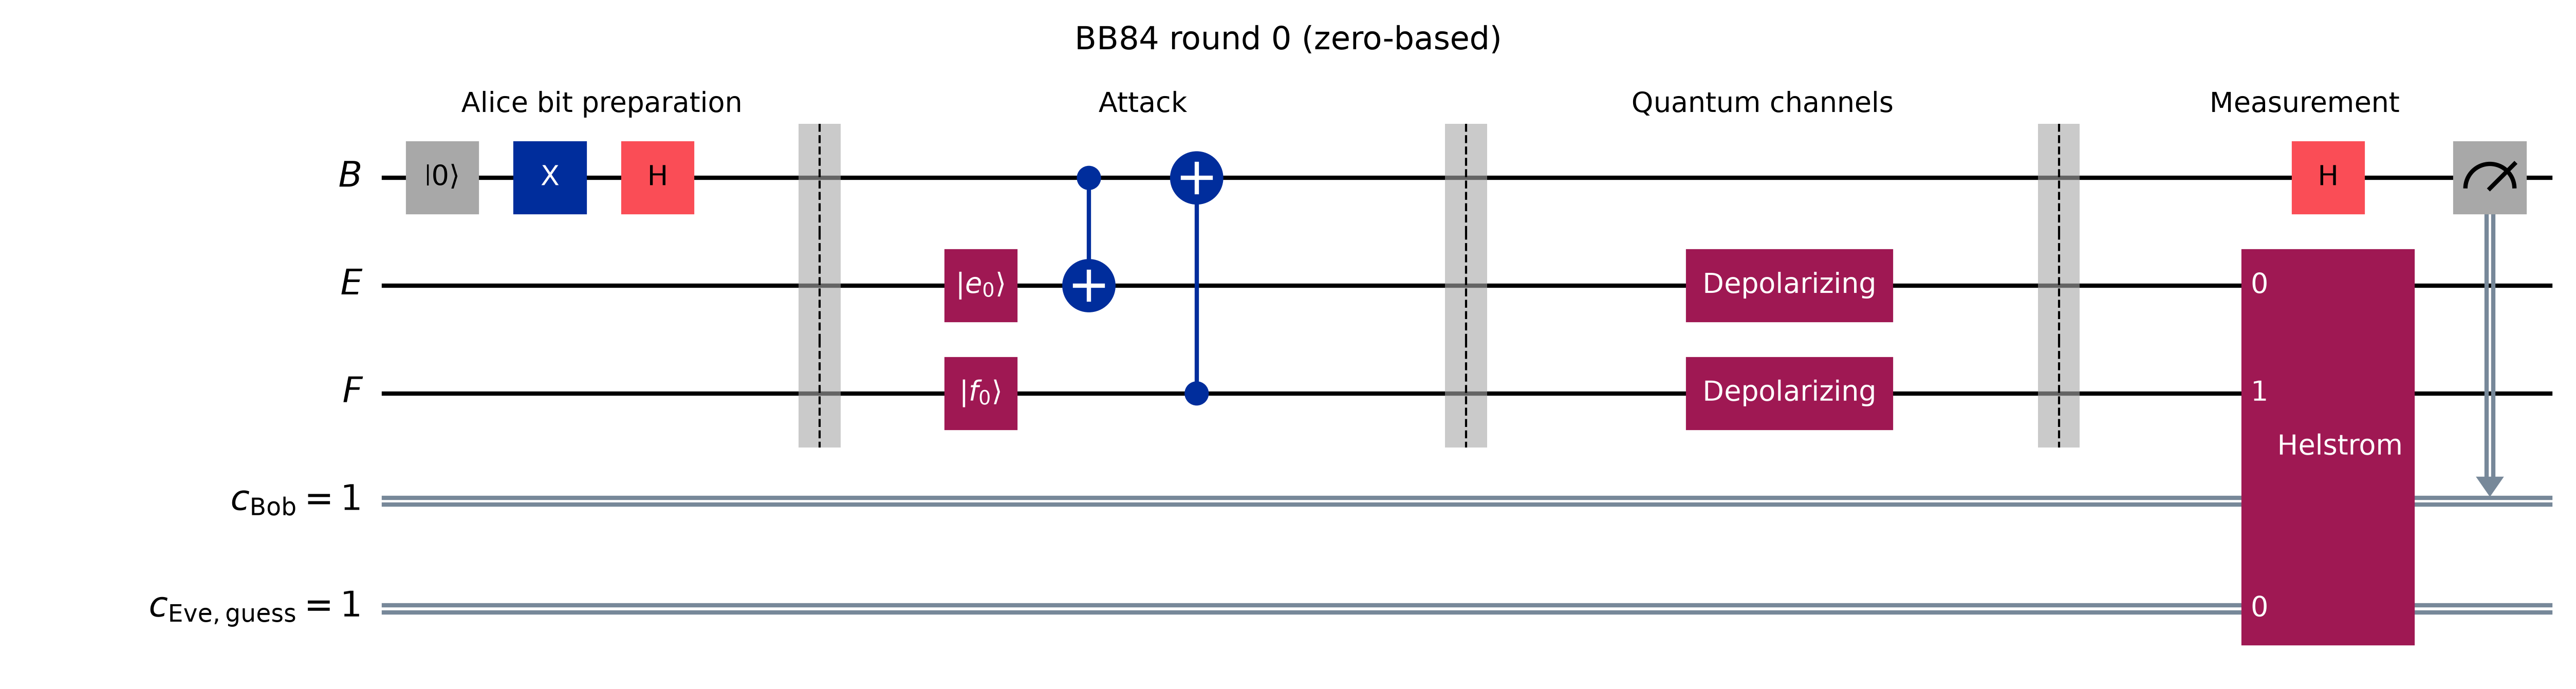

In [36]:
bb = BB84(seed=5, number_bits=N)
a = FGGNPAttack(seed=6)
bb.key_generation(a, memory_channel=Depolarizing(0.2), record_rounds=range(10))
bb.eve_guesses(readout="optimal", guess_on_erasure=True)
bb.display(round_index=0, show=False)
